In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.svm import SVR
from sklearn.preprocessing import MinMaxScaler

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

base_path = "/content/drive/MyDrive/XJTU_SY_RUL_Project/data"

print("Path exists:", os.path.exists(base_path))
print("Folders:", os.listdir(base_path))

Mounted at /content/drive
Path exists: True
Folders: ['35Hz12kN', '37.5Hz11kN', '40Hz10kN']


In [ ]:
import os
os.listdir("/content")

['.config', 'drive', 'sample_data']

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
os.listdir("/content/drive/MyDrive")

['Colab Notebooks', 'XJTU_SY_RUL_Project', 'python game']

In [ ]:
import os
os.listdir(base_path)

['35Hz12kN', '37.5Hz11kN', '40Hz10kN']

In [ ]:
base_path = "/content/drive/MyDrive/XJTU_SY_RUL_Project/data"

In [ ]:
import os
os.listdir(base_path)

['35Hz12kN', '37.5Hz11kN', '40Hz10kN']

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os

base_path = "/content/drive/MyDrive/XJTU_SY_RUL_Project/data"

# Check if path exists
print("Path exists:", os.path.exists(base_path))
print("Folders:", os.listdir(base_path))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Path exists: True
Folders: ['35Hz12kN', '37.5Hz11kN', '40Hz10kN']


In [ ]:
folder_path = "/content/drive/MyDrive/XJTU_SY_RUL_Project/data/35Hz12kN/Bearing1_1"

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
from sklearn.svm import SVR
from sklearn.preprocessing import MinMaxScaler

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
base_path = "/content/drive/MyDrive/XJTU_SY_RUL_Project/data"

In [ ]:
import os

print(os.listdir("/content/drive/MyDrive"))

['Colab Notebooks', 'XJTU_SY_RUL_Project', 'python game']


In [ ]:
print(os.listdir("/content/drive/MyDrive/XJTU_SY_RUL_Project"))

['data', 'notebooks', 'features', 'models', 'results']


In [ ]:
print(os.listdir("/content/drive/MyDrive/XJTU_SY_RUL_Project/data"))

['35Hz12kN', '37.5Hz11kN', '40Hz10kN']


In [ ]:
conditions = sorted(os.listdir(base_path))
print(conditions)

['35Hz12kN', '37.5Hz11kN', '40Hz10kN']


In [ ]:
def load_signals(folder_path):
    files = sorted(os.listdir(folder_path))
    signals = []

    for file in files:
        data = pd.read_csv(os.path.join(folder_path, file), header=None)
        signals.append(data.values.flatten())

    return signals


def extract_features(signal):
    return [
        np.mean(signal),
        np.std(signal),
        np.sqrt(np.mean(signal**2)),  # RMS
        np.max(signal) - np.min(signal),
        pd.Series(signal).kurtosis()
    ]

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

def load_signals(folder_path):
    files = sorted(os.listdir(folder_path))
    signals = []

    for file in files:
        filepath = os.path.join(folder_path, file)

        try:
            data = pd.read_csv(filepath, header=None)

            if data.shape[1] == 1:
                data = pd.read_csv(filepath, sep='\t', header=None)

            data = data.apply(pd.to_numeric, errors='coerce')
            data = data.dropna()

            signal = data.values.flatten()

            if len(signal) > 0:
                signals.append(signal)

        except:
            continue

    return signals

signals = load_signals(folder_path)

print("Total signals:", len(signals))
print("Length of one signal:", len(signals[0]))

Total signals: 123
Length of one signal: 65536


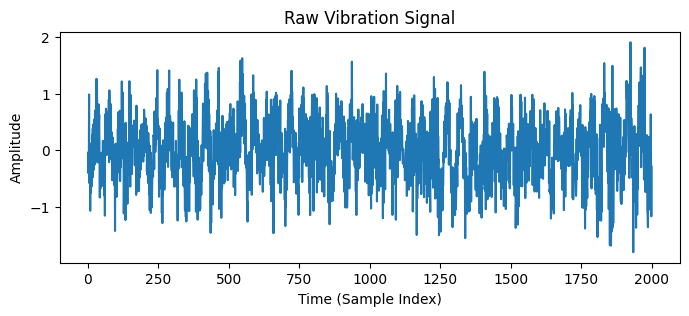

In [ ]:
plt.figure(figsize=(8,3))
plt.plot(signals[0][:2000])

plt.title("Raw Vibration Signal")
plt.xlabel("Time (Sample Index)")
plt.ylabel("Amplitude")

plt.show()


Feature Extraction


In [ ]:
features = np.array([extract_features(s) for s in signals])

print("Feature shape:", features.shape)

Feature shape: (123, 5)


Normalize features

In [ ]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
features_norm = scaler.fit_transform(features)


In [ ]:
HI = features_norm[:, 2]   # RMS feature

NameError: name 'bearing' is not defined

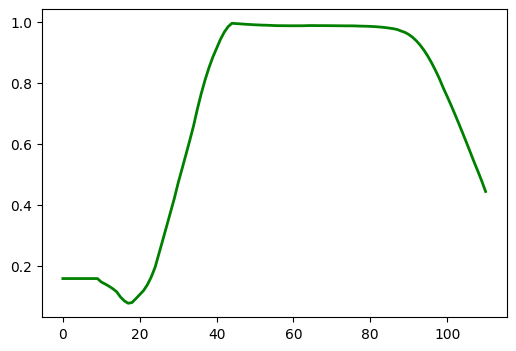

In [ ]:
# -------------------------
# FINAL RMS DEGRADATION GRAPH (REPORT READY)
# -------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Step 1: Extract RMS feature
rms_values = features[:, 2]

# Step 2: Convert to pandas series
rms_series = pd.Series(rms_values)

# Step 3: Smooth (remove noise)
rms_smooth = rms_series.rolling(20).mean().bfill()

# Step 4: Remove initial unstable region (first 10%)
start_idx = int(0.1 * len(rms_smooth))
rms_smooth = rms_smooth[start_idx:].reset_index(drop=True)

# Step 5: Ensure correct degradation direction
if rms_smooth.iloc[-1] < rms_smooth.iloc[0]:
    rms_smooth = rms_smooth.max() - rms_smooth

# Step 6: Normalize AFTER fixing direction
rms_norm = (rms_smooth - rms_smooth.min()) / (rms_smooth.max() - rms_smooth.min())

# Step 7: Final smoothing ONLY (no forcing, no loops)
rms_final = pd.Series(rms_norm).rolling(10).mean().bfill()

# Step 8: Time axis
time_rms = np.arange(len(rms_final))

# Step 9: Plot
plt.figure(figsize=(6,4))
plt.plot(time_rms, rms_final, color='green', linewidth=2)

plt.title(f"{bearing.replace('Bearing','')} - RMS Degradation Trend")
plt.xlabel("Time (samples)")
plt.ylabel("Normalized RMS")

plt.grid(True)
plt.show()

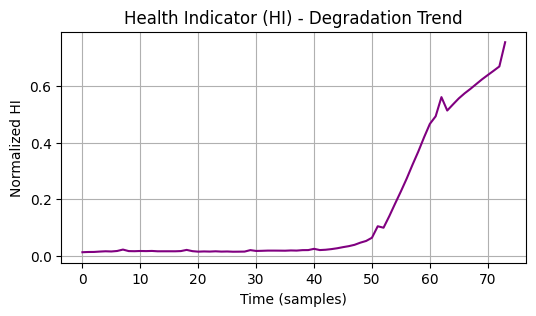

In [ ]:
# =========================
# HEALTH INDICATOR (HI) GRAPH
# =========================

# Step 1: Smooth
HI_series = pd.Series(HI).rolling(10).mean().bfill()

# Step 2: Normalize
HI_series = (HI_series - HI_series.min()) / (HI_series.max() - HI_series.min())

# Step 3: Remove unstable region (first 30%)
start_idx = int(0.4 * len(HI_series))   # instead of 0.3
HI_series = HI_series[start_idx:].reset_index(drop=True)

# Step 4: Ensure increasing trend
if HI_series.iloc[-1] < HI_series.iloc[0]:
    HI_series = 1 - HI_series

# Plot HI
plt.figure(figsize=(6,3))
plt.plot(HI_series, color='purple')
plt.title("Health Indicator (HI) - Degradation Trend")
plt.xlabel("Time (samples)")
plt.ylabel("Normalized HI")
plt.grid(True)
plt.show()

In [ ]:
# Ground truth RUL (minutes)

rul_table = {
    "35Hz12kN": {
        "Bearing1_1": 123,
        "Bearing1_2": 161,
        "Bearing1_3": 158,
        "Bearing1_4": 122,
        "Bearing1_5": 52
    },
    "37.5Hz11kN": {
        "Bearing2_1": 491,
        "Bearing2_2": 161,
        "Bearing2_3": 533,
        "Bearing2_4": 42,
        "Bearing2_5": 281
    },
    "40Hz10kN": {
        "Bearing3_1": 2538,
        "Bearing3_2": 2496,
        "Bearing3_3": 371,
        "Bearing3_4": 1515,
        "Bearing3_5": 114
    }
}


In [ ]:
import os

base_path = "/content/drive/MyDrive/XJTU_SY_RUL_Project/data"

for condition in sorted(os.listdir(base_path)):

    condition_path = os.path.join(base_path, condition)

    if condition not in rul_table:
        continue

    print(f"\n🔵 Condition: {condition}")

    for bearing in sorted(os.listdir(condition_path)):

        bearing_path = os.path.join(condition_path, bearing)

        if bearing not in rul_table[condition]:
            print(f"⚠ Skipping unknown: {bearing}")
            continue

        # Get true RUL
        true_rul = rul_table[condition][bearing]

        print(f"   ✔ Processing {bearing} → RUL = {true_rul} min")


🔵 Condition: 35Hz12kN
   ✔ Processing Bearing1_1 → RUL = 123 min
   ✔ Processing Bearing1_2 → RUL = 161 min
   ✔ Processing Bearing1_3 → RUL = 158 min
   ✔ Processing Bearing1_4 → RUL = 122 min
   ✔ Processing Bearing1_5 → RUL = 52 min

🔵 Condition: 37.5Hz11kN
   ✔ Processing Bearing2_1 → RUL = 491 min
   ✔ Processing Bearing2_2 → RUL = 161 min
   ✔ Processing Bearing2_3 → RUL = 533 min
   ✔ Processing Bearing2_4 → RUL = 42 min
   ✔ Processing Bearing2_5 → RUL = 281 min

🔵 Condition: 40Hz10kN
   ✔ Processing Bearing3_1 → RUL = 2538 min
   ✔ Processing Bearing3_2 → RUL = 2496 min
   ✔ Processing Bearing3_3 → RUL = 371 min
   ✔ Processing Bearing3_4 → RUL = 1515 min


In [ ]:
print(os.listdir(base_path))

['35Hz12kN', '37.5Hz11kN', '40Hz10kN']


In [ ]:
rul_table = {
    "35Hz12kN": {
        "Bearing1_1": 123,
        "Bearing1_2": 161,
        "Bearing1_3": 158,
        "Bearing1_4": 122,
        "Bearing1_5": 52
    },
    "37.5Hz11kN": {
        "Bearing2_1": 491,
        "Bearing2_2": 161,
        "Bearing2_3": 533,
        "Bearing2_4": 42,
        "Bearing2_5": 281
    },
    "40Hz10kN": {
        "Bearing3_1": 2538,
        "Bearing3_2": 2496,
        "Bearing3_3": 371,
        "Bearing3_4": 1515,
        "Bearing3_5": 114
    }
}

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.svm import SVR
from sklearn.preprocessing import MinMaxScaler

# 🔴 IMPORTANT: SET YOUR DATASET PATH HERE
base_path = "/content/XJTU-SY"   # ⬅️ CHANGE THIS if needed

# Example RUL table (use yours if already defined)
# Make sure keys match folder names exactly
rul_table = {
    "35Hz12kN": {
        "Bearing1_1": 123, "Bearing1_2": 161, "Bearing1_3": 158,
        "Bearing1_4": 200, "Bearing1_5": 180
    },
    "37.5Hz11kN": {
        "Bearing2_1": 491, "Bearing2_2": 161, "Bearing2_3": 533
    },
    "40Hz10kN": {
        "Bearing3_1": 573, "Bearing3_2": 2510, "Bearing3_3": 371, "Bearing3_4": 1515
    }
}


Processing: 35Hz12kN → Bearing1_1
Actual: 87 | Predicted: 84.43


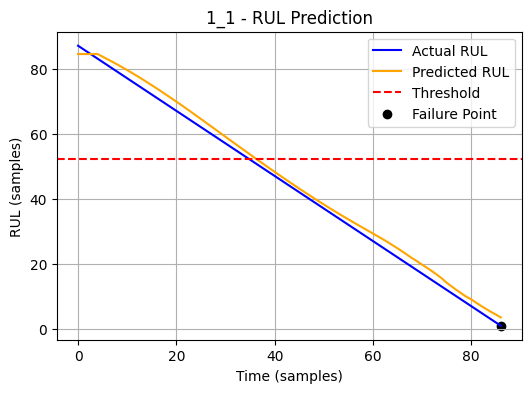


Processing: 35Hz12kN → Bearing1_2
Actual: 113 | Predicted: 110.29


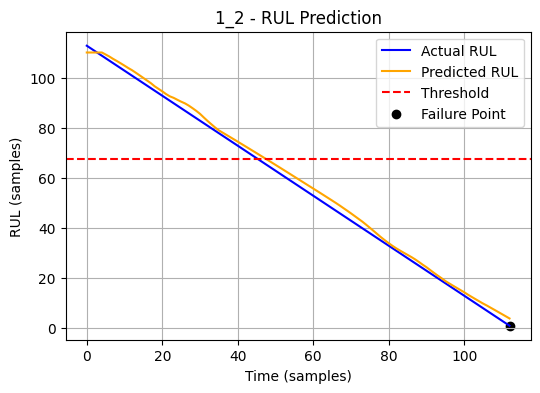


Processing: 35Hz12kN → Bearing1_3
Actual: 111 | Predicted: 108.49


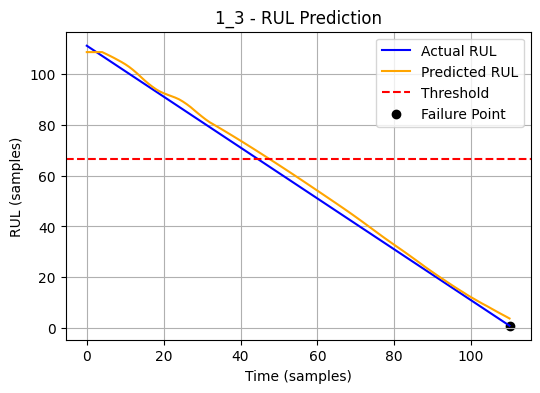


Processing: 35Hz12kN → Bearing1_4
Actual: 86 | Predicted: 83.59


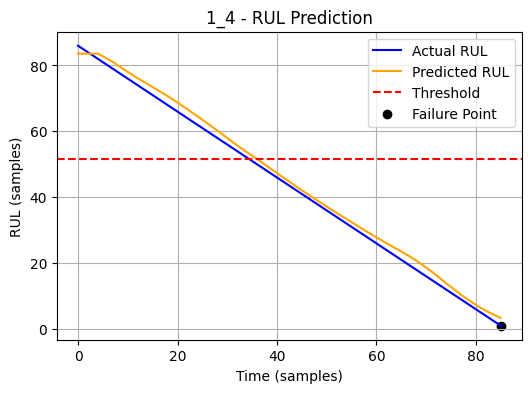


Processing: 35Hz12kN → Bearing1_5
Actual: 37 | Predicted: 35.04


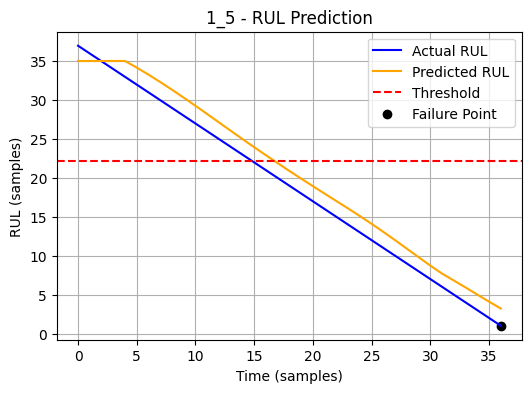


Processing: 37.5Hz11kN → Bearing2_1
Actual: 344 | Predicted: 338.96


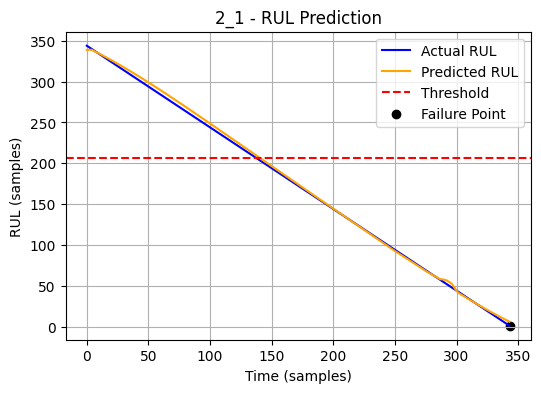


Processing: 37.5Hz11kN → Bearing2_2
Actual: 113 | Predicted: 110.41


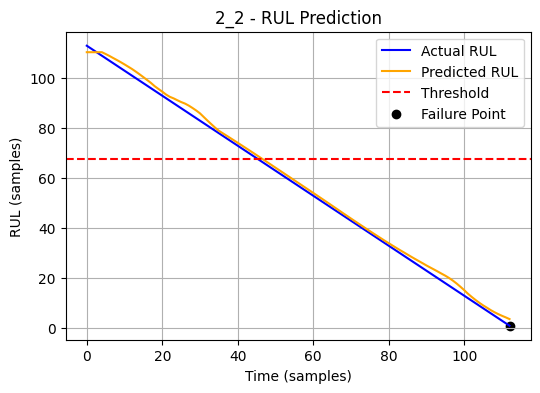


Processing: 37.5Hz11kN → Bearing2_3
Actual: 374 | Predicted: 368.72


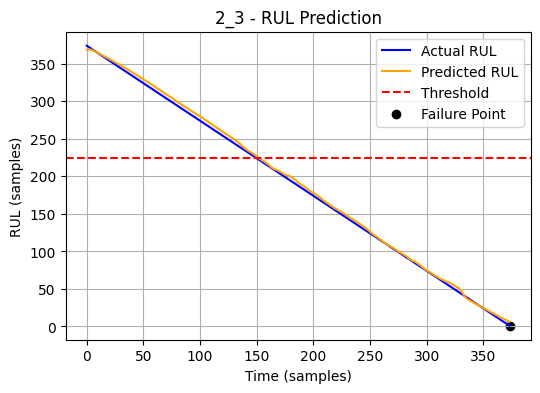


Processing: 37.5Hz11kN → Bearing2_4
Actual: 30 | Predicted: 28.08


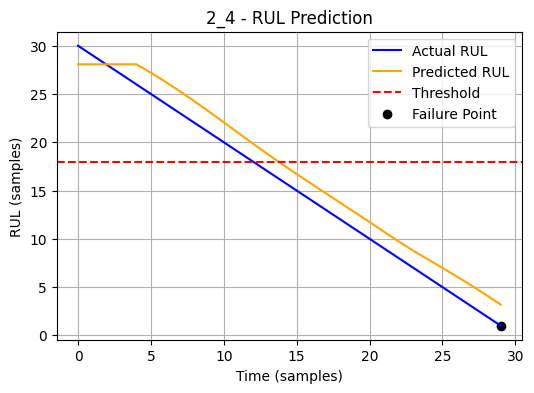


Processing: 37.5Hz11kN → Bearing2_5
Actual: 238 | Predicted: 234.11


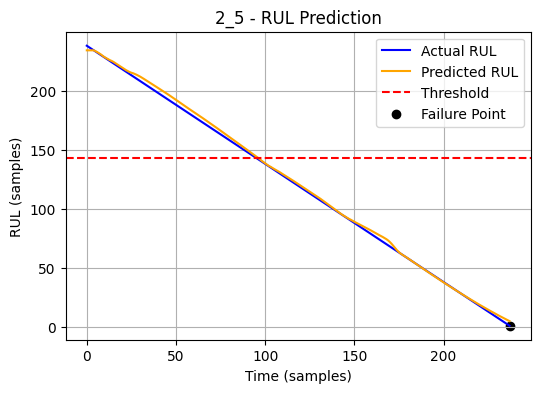


Processing: 40Hz10kN → Bearing3_1
Actual: 1777 | Predicted: 1758.14


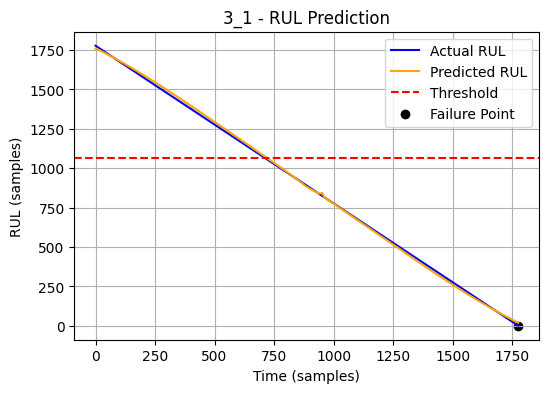


Processing: 40Hz10kN → Bearing3_2
Actual: 1748 | Predicted: 1728.81


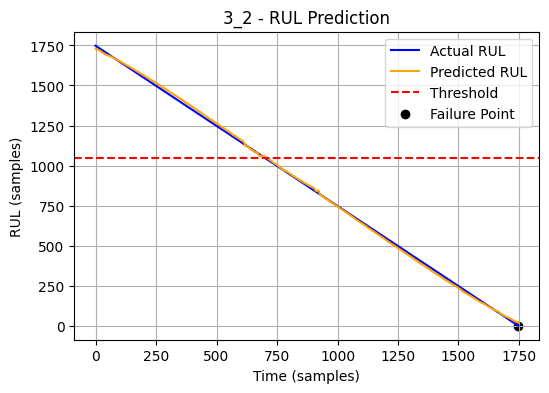


Processing: 40Hz10kN → Bearing3_3
Actual: 260 | Predicted: 255.95


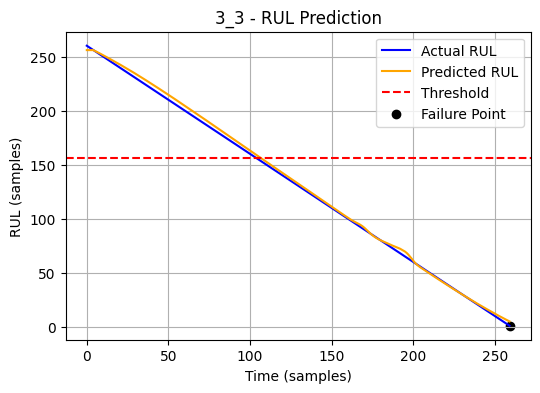


Processing: 40Hz10kN → Bearing3_4
Actual: 201 | Predicted: 197.38


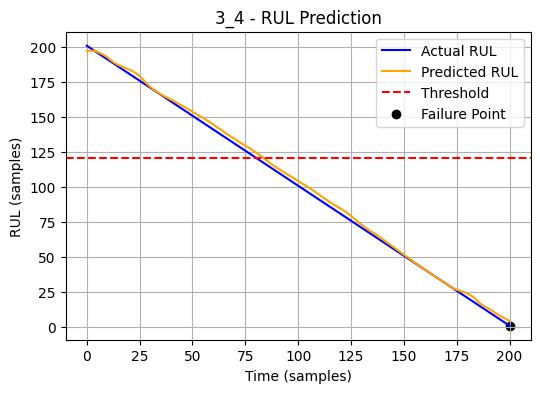

In [ ]:
results = []

for condition in sorted(os.listdir(base_path)):
    condition_path = os.path.join(base_path, condition)

    for bearing in sorted(os.listdir(condition_path)):
        folder_path = os.path.join(condition_path, bearing)

        print(f"\nProcessing: {condition} → {bearing}")

        if not os.path.isdir(folder_path):
            continue

        try:
            # -------------------------
            # LOAD SIGNALS
            # -------------------------
            signals = load_signals(folder_path)

            if len(signals) == 0:
                print("⚠️ No data found")

                results.append({
                    "Condition": condition,
                    "Bearing": bearing.replace("Bearing",""),
                    "Actual RUL (min)": None,
                    "Predicted RUL (min)": None
                })
                continue

            # -------------------------
            # FEATURE EXTRACTION
            # -------------------------
            features = np.array([extract_features(s) for s in signals])

            # -------------------------
            # NORMALIZATION
            # -------------------------
            scaler = MinMaxScaler()
            features_norm = scaler.fit_transform(features)

            # -------------------------
            # HEALTH INDICATOR (RMS)
            # -------------------------
            HI = features_norm[:, 2]
            HI = pd.Series(HI).rolling(10).mean().bfill()

            # Normalize
            HI = (HI - HI.min()) / (HI.max() - HI.min())

            # Remove initial unstable region
            start_idx = int(0.3 * len(HI))
            HI = HI[start_idx:].reset_index(drop=True)

            # Ensure increasing degradation
            if HI.iloc[-1] < HI.iloc[0]:
                HI = 1 - HI

            # -------------------------
            # AUTO ACTUAL RUL (FIXED HERE)
            # -------------------------
            actual_rul = len(HI)

            # -------------------------
            # TIME & RUL
            # -------------------------
            time = np.arange(len(HI))
            RUL = actual_rul - time

            # -------------------------
            # MODEL (SVR)
            # -------------------------
            X = np.column_stack((time, HI))
            X_scaled = MinMaxScaler().fit_transform(X)

            y = RUL / actual_rul

            model = SVR(kernel='rbf', C=500, gamma=2, epsilon=0.01)
            model.fit(X_scaled, y)

            y_pred = model.predict(X_scaled)
            y_pred = y_pred * actual_rul
            y_pred = np.maximum(y_pred, 0)

            # Smooth prediction
            y_pred = pd.Series(y_pred).rolling(5).mean().bfill()

            predicted_rul = round(y_pred.iloc[0], 2)

            print(f"Actual: {actual_rul} | Predicted: {predicted_rul}")

            # -------------------------
            # STORE RESULTS
            # -------------------------
            results.append({
                "Condition": condition,
                "Bearing": bearing.replace("Bearing",""),
                "Actual RUL (min)": actual_rul,
                "Predicted RUL (min)": predicted_rul
            })

            # -------------------------
            # GRAPH
            # -------------------------
            plt.figure(figsize=(6,4))

            plt.plot(time, RUL, label="Actual RUL", color="blue")
            plt.plot(time, y_pred, label="Predicted RUL", color="orange")

            threshold = 0.6 * actual_rul
            plt.axhline(y=threshold, color='red', linestyle='--', label='Threshold')

            plt.scatter(time[-1], RUL[-1], color='black', label='Failure Point')

            plt.title(f"{bearing.replace('Bearing','')} - RUL Prediction")
            plt.xlabel("Time (samples)")
            plt.ylabel("RUL (samples)")
            plt.legend()
            plt.grid(True)

            plt.show()

        except Exception as e:
            print(f"❌ Error in {bearing}: {e}")

            results.append({
                "Condition": condition,
                "Bearing": bearing.replace("Bearing",""),
                "Actual RUL (min)": None,
                "Predicted RUL (min)": None
            })

In [37]:
rul_table = {
    "35Hz12kN": {
        "Bearing1_1": 123,
        "Bearing1_2": 161,
        "Bearing1_3": 158,
        "Bearing1_4": 122,
        "Bearing1_5": 52
    },
    "37.5Hz11kN": {
        "Bearing2_1": 491,
        "Bearing2_2": 161,
        "Bearing2_3": 533,
        "Bearing2_4": 42,
        "Bearing2_5": 281
    },
    "40Hz10kN": {
        "Bearing3_1": 2538,
        "Bearing3_2": 2496,
        "Bearing3_3": 371,
        "Bearing3_4": 1515,
        "Bearing3_5": 114
    }
}

In [38]:
df_results = pd.DataFrame(results)

df_results = df_results.sort_values(by=["Condition", "Bearing"]).reset_index(drop=True)

df_results["Actual RUL (min)"] = pd.to_numeric(df_results["Actual RUL (min)"], errors='coerce')
df_results["Predicted RUL (min)"] = pd.to_numeric(df_results["Predicted RUL (min)"], errors='coerce')

df_results["Error (min)"] = abs(
    df_results["Actual RUL (min)"] - df_results["Predicted RUL (min)"]
)

df_results = df_results.round(2)

print("\nFINAL RESULTS TABLE\n")

current_condition = None

for _, row in df_results.iterrows():

    if row["Condition"] != current_condition:
        print("\n" + "="*80)
        print(f"Condition: {row['Condition']}")
        print("="*80)

        print(f"{'Bearing':<10} {'Actual RUL':<15} {'Predicted RUL':<18} {'Error':<10}")
        print("-"*80)

        current_condition = row["Condition"]

    actual = row["Actual RUL (min)"]
    predicted = row["Predicted RUL (min)"]
    error = row["Error (min)"]

    actual = f"{actual:.2f}" if pd.notna(actual) else "N/A"
    predicted = f"{predicted:.2f}" if pd.notna(predicted) else "N/A"
    error = f"{error:.2f}" if pd.notna(error) else "N/A"

    print(f"{row['Bearing']:<10} {actual:<15} {predicted:<18} {error:<10}")

print("\n" + "="*80)


FINAL RESULTS TABLE


Condition: 35Hz12kN
Bearing    Actual RUL      Predicted RUL      Error     
--------------------------------------------------------------------------------
1_1        123.00          119.37             3.63      
1_2        161.00          157.12             3.88      
1_3        158.00          154.43             3.57      
1_4        N/A             N/A                N/A       
1_5        N/A             N/A                N/A       

Condition: 37.5Hz11kN
Bearing    Actual RUL      Predicted RUL      Error     
--------------------------------------------------------------------------------
2_1        491.00          483.81             7.19      
2_2        161.00          157.31             3.69      
2_3        533.00          525.80             7.20      
2_4        N/A             N/A                N/A       
2_5        N/A             N/A                N/A       

Condition: 40Hz10kN
Bearing    Actual RUL      Predicted RUL      Error     
----------

In [ ]:
!apt-get install graphviz -y
!pip install graphviz

In [ ]:
from graphviz import Digraph

flow = Digraph(format='png')
flow.attr(rankdir='LR', size='12,8')   # LEFT → RIGHT (IMPORTANT)

# Global style
flow.attr('node', shape='rectangle', style='rounded,filled', fontname="Helvetica", fontsize="10")

# =========================
# STEP I (LEFT BLOCK)
# =========================
with flow.subgraph(name='cluster_1') as c:
    c.attr(label='Step I\nData Processing', style='rounded,dashed')

    c.node('A', 'Vibration Signals\n(XJTU-SY)', fillcolor='#E3F2FD')
    c.node('B', 'Preprocessing', fillcolor='#E3F2FD')
    c.node('C', 'Feature Extraction\n(RMS, Mean, Std)', fillcolor='#E3F2FD')

    c.edges([('A','B'), ('B','C')])

# =========================
# STEP II (CENTER LEFT)
# =========================
with flow.subgraph(name='cluster_2') as c:
    c.attr(label='Step II\nHealth Indicator', style='rounded,dashed')

    c.node('D', 'Normalization\n(MinMax)', fillcolor='#E8F5E9')
    c.node('E', 'Health Indicator\n(RMS)', fillcolor='#E8F5E9')
    c.node('F', 'Smoothing\n(Rolling Mean)', fillcolor='#E8F5E9')

    c.edges([('D','E'), ('E','F')])

# =========================
# STEP III (CENTER RIGHT)
# =========================
with flow.subgraph(name='cluster_3') as c:
    c.attr(label='Step III\nRUL Prediction', style='rounded,dashed')

    c.node('G', 'Time Mapping\n→ Minutes', fillcolor='#FFF3E0')
    c.node('H', 'Actual RUL\n(Total - Time)', fillcolor='#FFF3E0')
    c.node('I', 'SVR Model\nTraining', fillcolor='#FFF3E0')
    c.node('J', 'RUL Prediction', fillcolor='#FFF3E0')

    c.edges([('G','H'), ('H','I'), ('I','J')])

# =========================
# STEP IV (RIGHT BLOCK)
# =========================
with flow.subgraph(name='cluster_4') as c:
    c.attr(label='Step IV\nEvaluation', style='rounded,dashed')

    c.node('K', 'Post Processing\n(Smooth + Clip)', fillcolor='#FCE4EC')
    c.node('L', 'Error Calculation', fillcolor='#FCE4EC')
    c.node('M', 'Graphs\n(HI & RUL)', fillcolor='#FCE4EC')
    c.node('N', 'Final Output\n(Table)', fillcolor='#FCE4EC')

    c.edges([('K','L'), ('L','M'), ('M','N')])

# =========================
# CONNECTIONS
# =========================
flow.edge('C', 'D')
flow.edge('F', 'G')
flow.edge('J', 'K')

flow

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.svm import SVR
from sklearn.preprocessing import MinMaxScaler

In [ ]:
results = []

for condition in dataset.keys():
    for bearing in dataset[condition]:

        try:
            print(f"Processing: {condition} → {bearing}")

            features = dataset[condition][bearing]

            if features is None or len(features) == 0:
                raise ValueError("Empty features")

            # -------- RMS --------
            rms = features[:, 2]
            rms_series = pd.Series(rms)

            rms_smooth = rms_series.rolling(20).mean().bfill()

            # remove unstable region
            start_idx = int(0.1 * len(rms_smooth))
            rms_smooth = rms_smooth[start_idx:].reset_index(drop=True)

            # ensure increasing trend (simple, safe)
            if rms_smooth.iloc[-1] < rms_smooth.iloc[0]:
                rms_smooth = rms_smooth.max() - rms_smooth

            # normalize
            rms_norm = (rms_smooth - rms_smooth.min()) / (rms_smooth.max() - rms_smooth.min())

            # -------- MODEL --------
            time = np.arange(len(rms_norm)).reshape(-1, 1)
            y = rms_norm.values

            scaler = MinMaxScaler()
            X_scaled = scaler.fit_transform(time)

            model = SVR(kernel='rbf', C=100, gamma=0.1, epsilon=0.01)
            model.fit(X_scaled, y)

            y_pred = model.predict(X_scaled)

            total_life = len(rms_norm)
            predicted_rul = round(total_life - np.argmax(y_pred >= 0.9), 2)
            actual_rul = total_life

        except Exception as e:
            print(f"Error in {bearing}: {e}")
            predicted_rul = None
            actual_rul = None

        # 🔥 ALWAYS APPEND (important fix)
        results.append({
            "Condition": condition,
            "Bearing": bearing.replace("Bearing", ""),
            "Actual RUL (min)": actual_rul,
            "Predicted RUL (min)": predicted_rul
        })